In [147]:
library(tidyverse)
library(tximport)
library(DESeq2)
library(rtracklayer)
library(ggrepel)
library(RColorBrewer)
library(pheatmap)
library(patchwork)
library(ggrastr)
library(gridExtra)

theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))

In [2]:
#GENCODE annotations
gtf.file <- "/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.gtf.gz"
gencode <- import(gtf.file)
gencode <- gencode[which(gencode$type=="gene")]
#read in TSS coordinates w/ genes
gencode_tss <- read.delim("/mnt/disk/home/agulka/projects/poised_enh_manuscript/inputs/GENCODE/gencode.v47.annotation.transcripts_tss.1kb.bed", header=F, sep='\t')

In [63]:
#generate rowdata
row.data <- data.frame(gencode@elementMetadata)
rownames(row.data) <- row.data$gene_id
row.data$gene_id <- NULL
#generate column with cleaned ENSEMBL IDs
row.data$gene_id_base <- gsub("\\..*$", "", rownames(row.data)) 
#remove NA columns
row.data <- row.data[,colSums(is.na(row.data))<nrow(row.data)]
# add genome coordinates
row.data$chr <- as.character(gencode@seqnames)
row.data$start <- as.numeric(gencode@ranges@start)
row.data$end <- row.data$start + as.numeric(gencode@ranges@width)

row.data <- row.data %>% filter(gene_type=="protein_coding")

In [64]:
#read in TPM and counts data
path <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/RSEM/GM12878/stimulus_bafinh"
files <- list.files(path, pattern="results", full.name=TRUE)
txi <- tximport(files,type="rsem", txIn=FALSE)

reading in files with read_tsv

1 
2 
3 
4 
5 
6 
7 
8 
9 
10 
11 
12 
13 
14 
15 
16 
17 
18 
19 
20 
21 
22 
23 
24 




In [65]:
#make column metadata
parse_file <- function(filename) {
  parts <- str_split(filename, "_", simplify = TRUE)

  # find the column that matches r<digit>
  rep_idx <- which(str_detect(parts, "^r\\d+$"))

  timepoint <- parts[2]                     # T1
  replicate <- parts[rep_idx]               # r1, r2, ...
  treatment_vec <- parts[3:(rep_idx - 1)]   # BRM or BRM_Dex
  treatment <- paste(treatment_vec, collapse = "_")

  tibble(
    filename = filename,
    timepoint = timepoint,
    treatment = treatment,
    replicate = replicate
  )
}

files <- list.files(path, pattern="results")
col.data <- do.call(rbind, lapply(files, parse_file)) %>% mutate(group=paste0(treatment,"_", timepoint))
col.data

filename,timepoint,treatment,replicate,group
<chr>,<chr>,<chr>,<chr>,<chr>
rep1_T1_BRM_Dex_r1_anno_rsem.genes.results,T1,BRM_Dex,r1,BRM_Dex_T1
rep1_T1_BRM_Dex_r2_anno_rsem.genes.results,T1,BRM_Dex,r2,BRM_Dex_T1
rep1_T1_BRM_IFN_r1_anno_rsem.genes.results,T1,BRM_IFN,r1,BRM_IFN_T1
rep1_T1_BRM_IFN_r2_anno_rsem.genes.results,T1,BRM_IFN,r2,BRM_IFN_T1
rep1_T1_BRM_r1_anno_rsem.genes.results,T1,BRM,r1,BRM_T1
rep1_T1_BRM_r2_anno_rsem.genes.results,T1,BRM,r2,BRM_T1
rep1_T1_Dex_r1_anno_rsem.genes.results,T1,Dex,r1,Dex_T1
rep1_T1_Dex_r2_anno_rsem.genes.results,T1,Dex,r2,Dex_T1
rep1_T1_IFN_r1_anno_rsem.genes.results,T1,IFN,r1,IFN_T1


In [66]:
#filter txi object
nrow(txi$abundance)
#first, filter to exclude non-protein coding genes using the row metadata
txi$abundance <- txi$abundance[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$abundance))),] 
txi$counts <- txi$counts[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$counts))),]
txi$length <- txi$length[match(row.data$gene_id_base, gsub("\\..*$", "", rownames(txi$length))),]
nrow(txi$abundance)
#next, filter to remove lowly-expressed and 0-length genes
filt <- which(apply(txi$abundance,MARGIN=1,FUN=max) <= 1 | #genes with low expression (where max TPM for all samples is <=1)
                apply(txi$length, MARGIN=1,FUN=min)==0) #genes with weird annotations (length=0)

#filter out these genes from txi object
txi$abundance <- txi$abundance[-filt,]
txi$counts <- txi$counts[-filt,]
txi$length <- txi$length[-filt,]

#get rid of any NA rows
txi$counts <- txi$counts[-which(!rowSums(is.finite(txi$abundance))),]
txi$length <- txi$length[-which(!rowSums(is.finite(txi$abundance))),]
txi$abundance <- txi$abundance[-which(!rowSums(is.finite(txi$abundance))),]
nrow(txi$abundance)
     
#filter row metadata to match rows of filtered txi object
row.data <- row.data[match(gsub("\\..*$", "", 
                                rownames(txi$abundance)), 
                           row.data$gene_id_base),]
nrow(txi$abundance)
nrow(row.data)

[1] 59526

[1] 20092

[1] 12190

[1] 12190

[1] 12190

In [67]:
deg_res <- function (des, row.data, contrast) 
{
    res <- results(des, contrast = contrast)
    res <- res %>% data.frame() %>% rownames_to_column("ENSEMBL_ID") %>% 
            mutate(gene=row.data$gene_name,change = case_when(log2FoldChange > log2(1.5) & 
                                      padj < 0.05 ~ "up", 
                                      log2FoldChange < -log2(1.5) & padj < 0.05 ~ "down", 
                                      TRUE ~ "ns"))
    return(res)
}

dds <- DESeqDataSetFromTximport(txi,col.data, design=~group)
des <- DESeq(dds)

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”
using counts and average transcript lengths from tximport

estimating size factors

using 'avgTxLength' from assays(dds), correcting for library size

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [183]:
ifn_1h <- deg_res(des, row.data, c("group", "IFN_T1", "Veh_T1"))
ifn_6h <- deg_res(des, row.data, c("group", "IFN_T6", "Veh_T6"))
dex_1h <- deg_res(des, row.data, c("group", "Dex_T1", "Veh_T1"))
dex_6h <- deg_res(des, row.data, c("group", "Dex_T6", "Veh_T6"))

brm_ifn_1h <- deg_res(des, row.data, c("group", "BRM_IFN_T1", "IFN_T1"))
brm_dex_1h <- deg_res(des, row.data, c("group", "BRM_Dex_T1", "Dex_T1"))
brm_ifn_6h <- deg_res(des, row.data, c("group", "BRM_IFN_T6", "IFN_T6"))
brm_dex_6h <- deg_res(des, row.data, c("group", "BRM_Dex_T6", "Dex_T6"))

brm_ifn_veh_1h <- deg_res(des, row.data, c("group", "BRM_IFN_T1", "Veh_T1"))
brm_dex_veh_1h <- deg_res(des, row.data, c("group", "BRM_Dex_T1", "Veh_T1"))
brm_ifn_veh_6h <- deg_res(des, row.data, c("group", "BRM_IFN_T6", "Veh_T6"))
brm_dex_veh_6h <- deg_res(des, row.data, c("group", "BRM_Dex_T6", "Veh_T6"))


brm_1h <- deg_res(des, row.data, c("group", "BRM_T1", "Veh_T1"))
brm_6h <- deg_res(des, row.data, c("group", "BRM_T6", "Veh_T6"))

In [9]:
ifn_up <- which(ifn_1h$change=="up" | ifn_6h$change=="up")
dex_up <- which(dex_1h$change=="up" | dex_6h$change=="up")
ifn_down <- which(ifn_1h$change=="down" | ifn_6h$change=="down")
dex_down <- which(dex_1h$change=="down" | dex_6h$change=="down")

In [167]:
volcano <- function(table, rowdat, q_thresh=0.05, fc_thresh=log2(1.5), main="", top_n=10){
    temp <- table %>% mutate(gene=rowdat$gene_name) %>% 
            na.omit() %>%
            mutate(change = case_when(log2FoldChange > fc_thresh & 
                                      padj < q_thresh ~ "up", 
                                      log2FoldChange < -fc_thresh & padj < q_thresh ~ "down", 
                                      TRUE ~ "ns"))
    xmax <- max(abs(temp$log2FoldChange))
    n_down <- table(temp$change)[1]
    n_up <- table(temp$change)[3]

    #top10_up <- temp[temp$change=="up",] %>% arrange(desc(log2FoldChange)) %>% head(top_n)
    #top10_down <- temp[temp$change=="down",] %>% arrange(log2FoldChange) %>% head(top_n)
    top10s <- temp[temp$change == "up",] %>% arrange(desc(abs(log2FoldChange))) %>% head(top_n)

    ggplot(temp, aes(color=change, x=log2FoldChange,y=-log10(padj))) +
        geom_point(size=.5) +
        geom_vline(xintercept=c(-fc_thresh, fc_thresh), linetype=2) + 
        geom_hline(yintercept=-log10(q_thresh), linetype=2) + 
        xlim(-xmax, xmax) +
        scale_color_manual(values=c("down"=brewer.pal(3,"Paired")[2], "ns"="grey", "up"=brewer.pal(6,"Paired")[6])) +
        geom_text_repel(data=top10s, aes(label=gene), size=2, min.segment.length = 0, max.overlaps=100) +
        ggtitle(main, subtitle=paste("Down:", n_down, "; Up:", n_up)) 
}

hm_scale <- function(tpms,coldata,groups, scale="none", breaks=NA, colors=c("white", "red")){
    temp <- tpms[,coldata$group %in% groups] %>% +1 %>% log2()
    temp_coldata <- coldata[coldata$group %in% groups,]
    max <- max(temp) + 1
    
    d <- dist(scale(temp))
    h <- hclust(d)
    
    pheatmap(temp[h$order,], 
             color=colorRampPalette(colors)(100), 
             cluster_rows=if (scale=="row") TRUE else FALSE, 
             cluster_cols=FALSE, 
             border_col=NA, 
             labels_col=temp_coldata$group,
             show_rownames=FALSE,
             scale=scale,
             breaks= breaks,
             cellheight=1, 
             main=paste("n=", nrow(temp)))
}

In [71]:
ifn_volcanos <- (volcano(ifn_1h, row.data) / volcano(ifn_6h, row.data))
dex_volcanos <- (volcano(dex_1h, row.data) / volcano(dex_6h, row.data))

In [72]:
#one option - volcano plot (issue imo is that it doesn't capture similarity between responses)
volcano <- ifn_volcanos | dex_volcanos
ggsave("panelc_volcano.pdf", volcano, width=9)

Saving 9 x 7 in image


In [184]:
#write out DEGs
dir <- "~/manuscripts/BAF_stimulus_CellGenomics/inputs/DEGs/GM12878/BAFinh_stimulus/"
write.table(ifn_1h, paste0(dir,"IFNy_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(ifn_6h, paste0(dir,"IFNy_6h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(dex_1h, paste0(dir,"Dex_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(dex_6h, paste0(dir,"Dex_6h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_1h, paste0(dir,"BRM_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_6h, paste0(dir,"BRM_6h_DEGs.tsv"), sep='\t', row.names=FALSE)

write.table(brm_ifn_1h, paste0(dir,"BRM_IFNy_v_IFNy_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_dex_1h, paste0(dir,"BRM_Dex_v_Dex_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_ifn_6h, paste0(dir,"BRM_IFNy_v_IFNy_6h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_dex_6h, paste0(dir,"BRM_Dex_v_Dex_6h_DEGs.tsv"), sep='\t', row.names=FALSE)

write.table(brm_ifn_veh_1h, paste0(dir,"BRM_IFNy_v_Veh_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_dex_veh_1h, paste0(dir,"BRM_Dex_v_Veh_1h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_ifn_veh_6h, paste0(dir,"BRM_IFNy_v_Veh_6h_DEGs.tsv"), sep='\t', row.names=FALSE)
write.table(brm_dex_veh_6h, paste0(dir,"BRM_Dex_v_Veh_6h_DEGs.tsv"), sep='\t', row.names=FALSE)

write.table(row.data, "IFNy_Dex_DEGs_rowdata.tsv", sep='\t', row.names=FALSE)
write.table(txi$abundance, "IFNy_Dex_DEGs_TPMs.tsv", sep='\t', row.names=FALSE)
write.table(col.data, "IFNy_Dex_DEGs_coldata.tsv", sep='\t', row.names=FALSE)

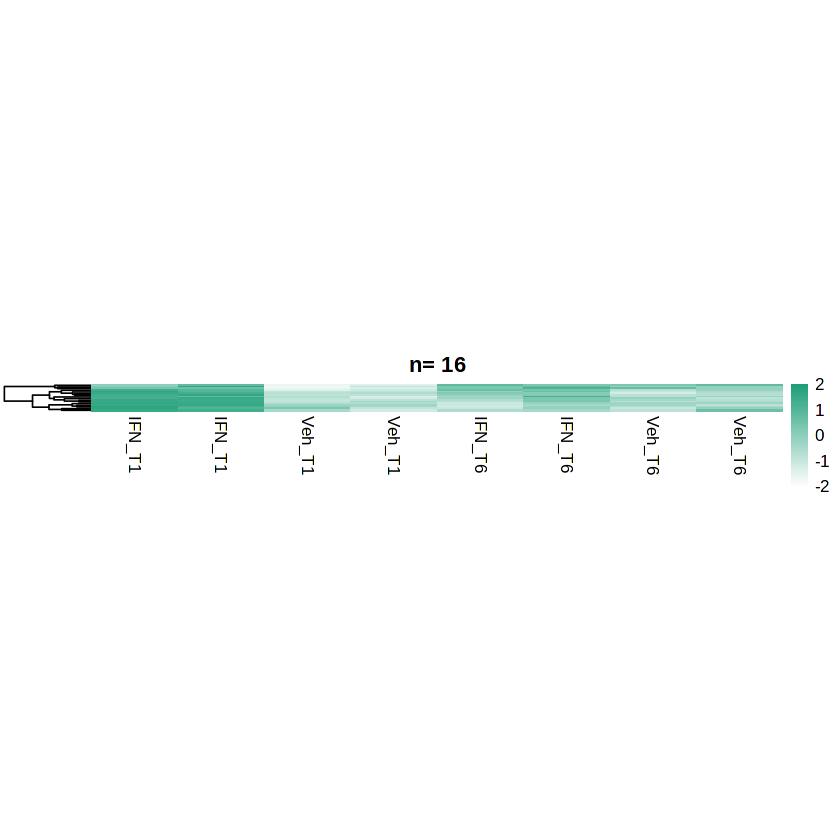

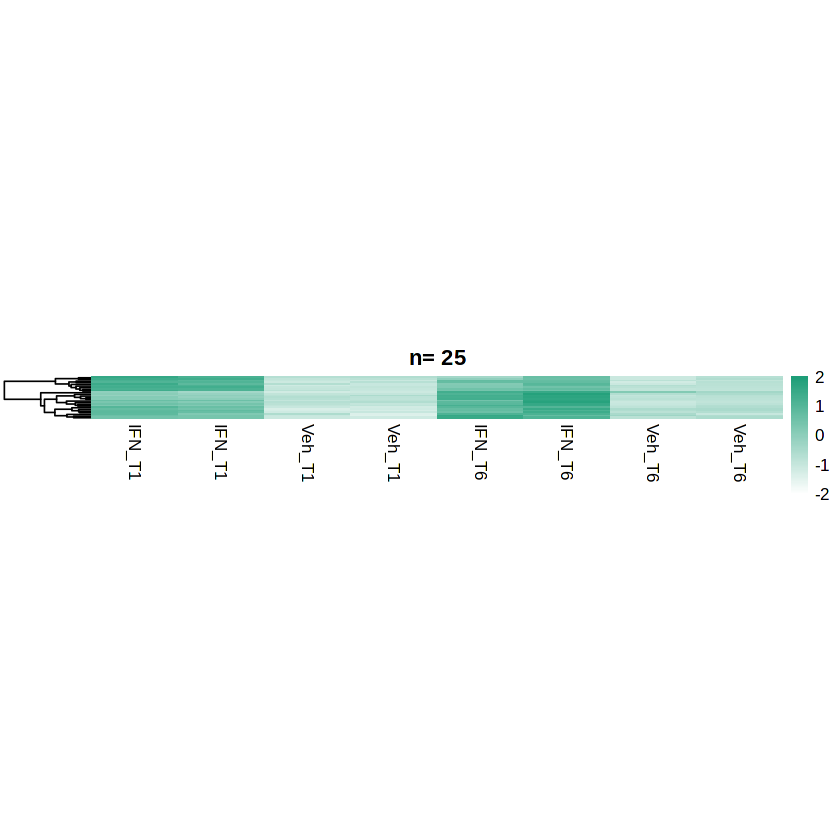

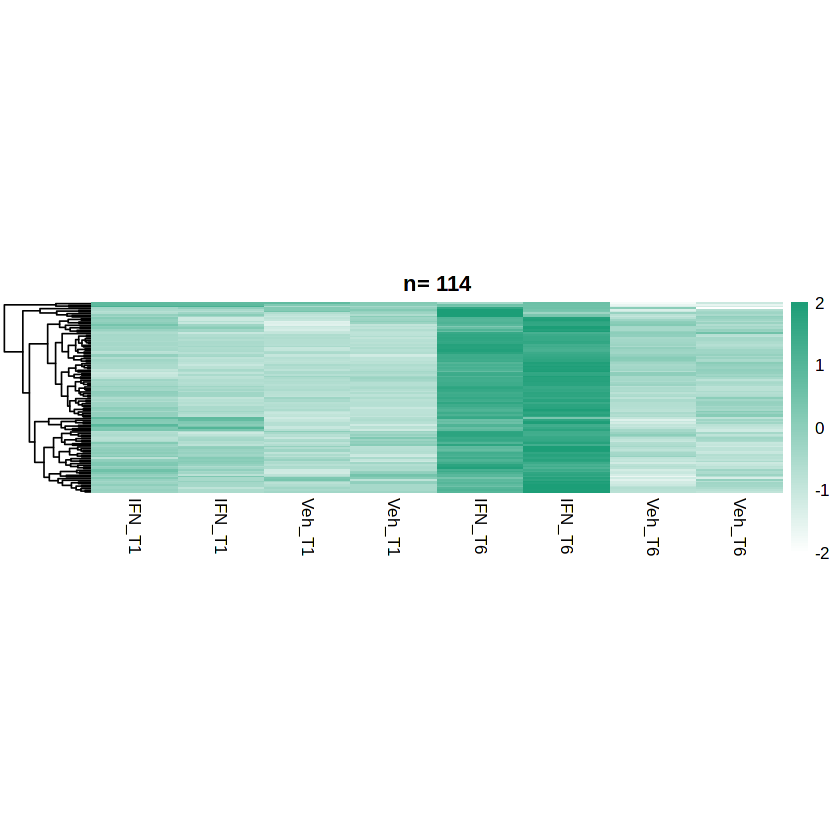

Saving 3 x 7 in image


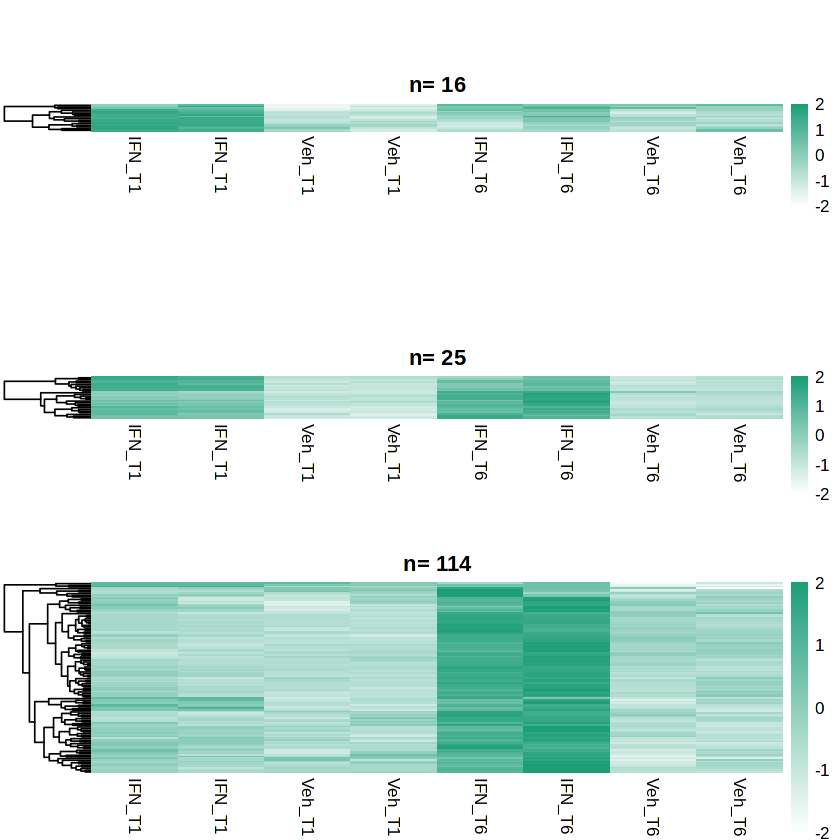

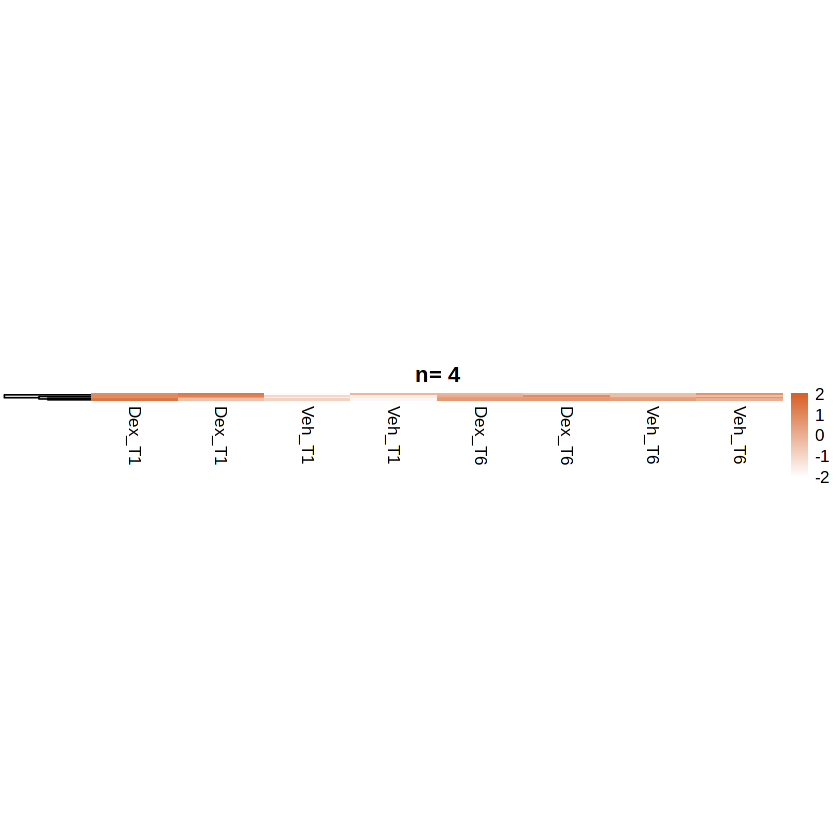

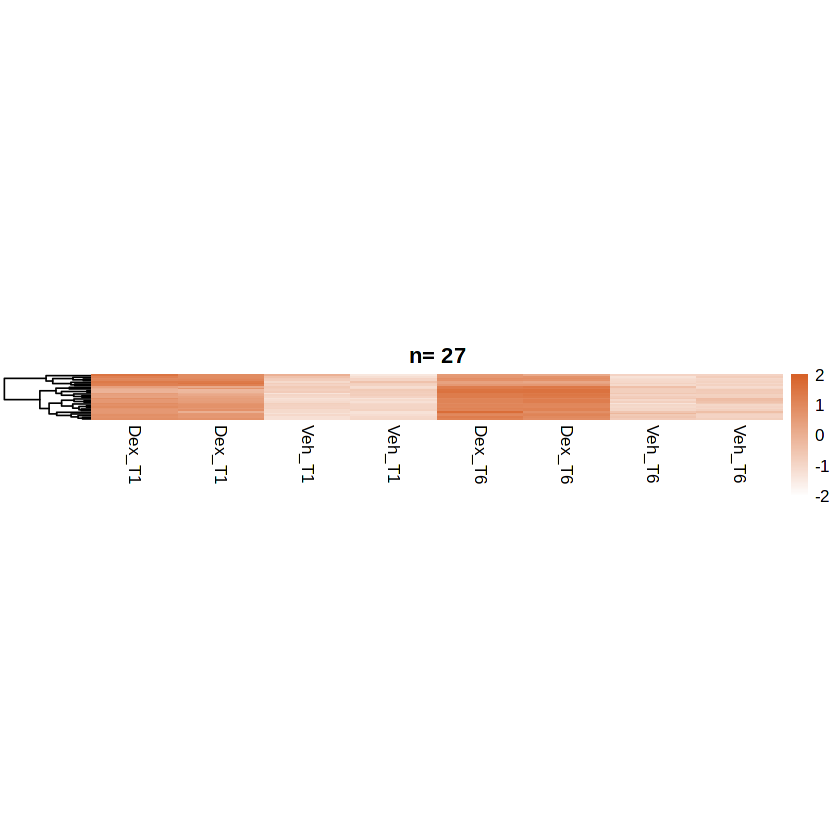

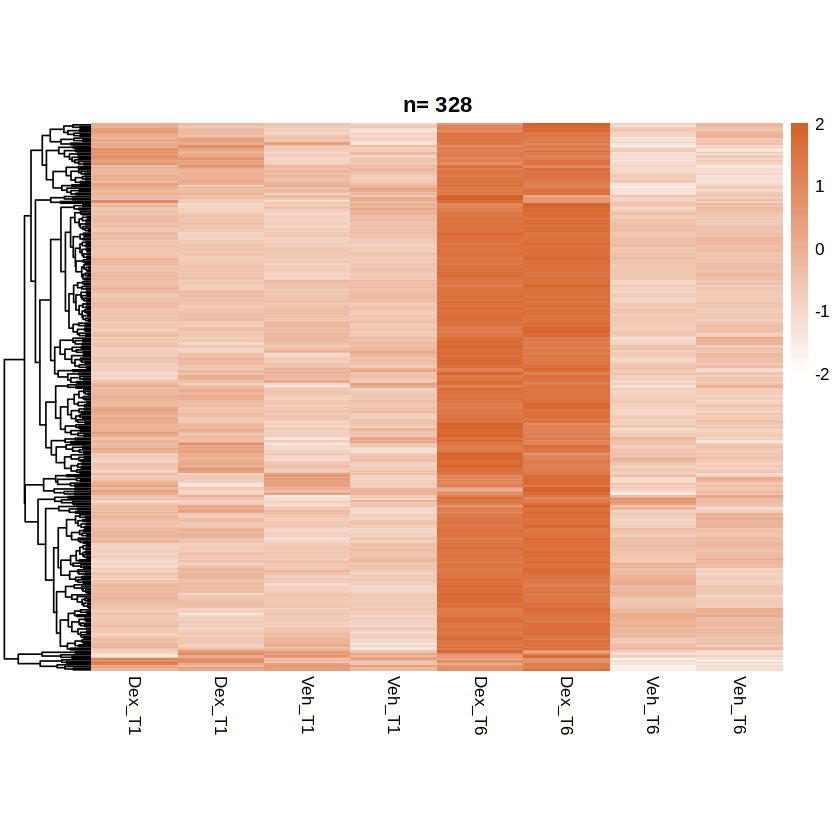

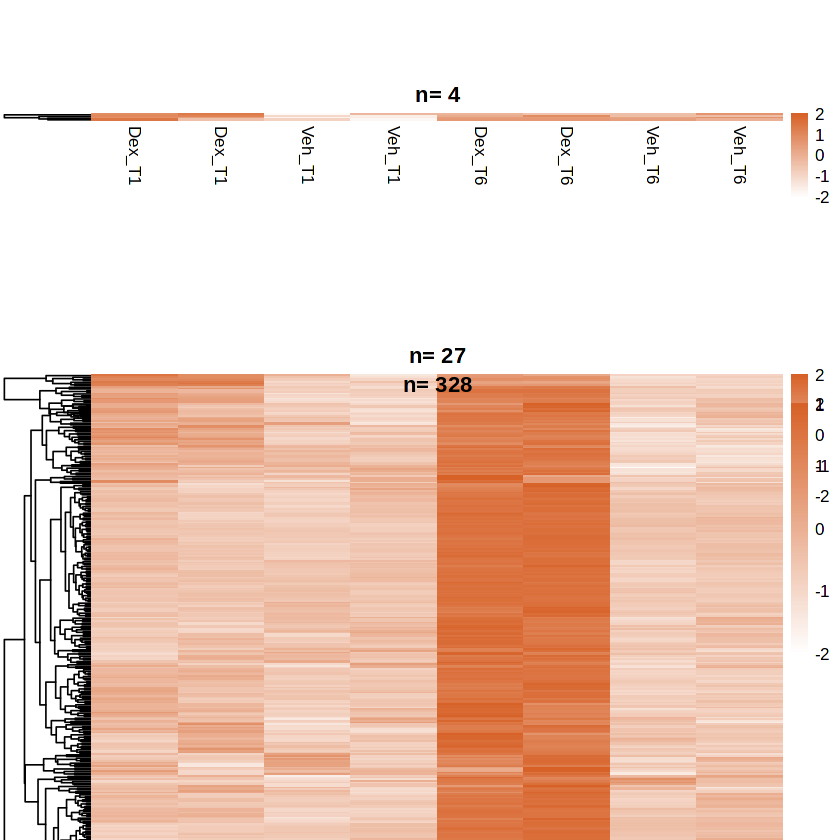

In [168]:
#heatmaps of inducible genes for each stimulus, separated into timepoint-specific and shared DEGs
up_1h <- hm_scale(tpms=txi$abundance[ifn_1h$change=="up" & ifn_6h$change != "up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "IFN_T1", "IFN_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#1c9e77"))
up_both <- hm_scale(tpms=txi$abundance[ifn_1h$change=="up" & ifn_6h$change=="up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "IFN_T1", "IFN_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#1c9e77"))
up_6h <- hm_scale(tpms=txi$abundance[ifn_1h$change!="up" & ifn_6h$change=="up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "IFN_T1", "IFN_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#1c9e77"))
up_all <- grid.arrange(up_1h$gtable, up_both$gtable, up_6h$gtable)
ggsave("hm_all_ifn_up.pdf",up_all, width=3)

up_1h <- hm_scale(tpms=txi$abundance[dex_1h$change=="up" & dex_6h$change != "up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "Dex_T1", "Dex_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#d76127"))
up_both <- hm_scale(tpms=txi$abundance[dex_1h$change=="up" & dex_6h$change=="up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "Dex_T1", "Dex_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#d76127"))
up_6h <- hm_scale(tpms=txi$abundance[dex_1h$change!="up" & dex_6h$change=="up",], coldata=col.data, groups=c("Veh_T1", "Veh_T6", "Dex_T1", "Dex_T6"), scale="row", breaks=seq(-2,2,length.out=100), colors=c("white", "#d76127"))
up_all <- grid.arrange(up_1h$gtable, up_both$gtable, up_6h$gtable)
ggsave("hm_all_dex_up.pdf",up_all, width=3, height=15)

In [283]:
row.data[ifn_1h$change=="ns" & ifn_6h$change=="up",]

,source,type,gene_type,gene_name,level,tag,hgnc_id,havana_gene,artif_dupl,gene_id_base,chr,start,end
,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
ENSG00000116663.11,HAVANA,gene,protein_coding,FBXO6,2,NA,HGNC:13585,OTTHUMG00000002229.2,NA,ENSG00000116663,chr1,11664200,11674355
ENSG00000126709.16,HAVANA,gene,protein_coding,IFI6,2,NA,HGNC:4054,OTTHUMG00000003518.2,NA,ENSG00000126709,chr1,27666064,27672213
ENSG00000158156.9,HAVANA,gene,protein_coding,XKR8,2,NA,HGNC:25508,OTTHUMG00000003912.2,NA,ENSG00000158156,chr1,27959588,27968094
ENSG00000081985.14,HAVANA,gene,protein_coding,IL12RB2,2,NA,HGNC:5972,OTTHUMG00000009094.7,NA,ENSG00000081985,chr1,67307364,67398725
ENSG00000162614.19,HAVANA,gene,protein_coding,NEXN,2,NA,HGNC:29557,OTTHUMG00000040533.4,NA,ENSG00000162614,chr1,77888513,77943896
ENSG00000117226.13,HAVANA,gene,protein_coding,GBP3,1,ncRNA_host,HGNC:4184,OTTHUMG00000010616.9,NA,ENSG00000117226,chr1,89006666,89022895
ENSG00000162645.13,HAVANA,gene,protein_coding,GBP2,2,overlapping_locus,HGNC:4183,OTTHUMG00000010662.5,NA,ENSG00000162645,chr1,89106132,89150457
ENSG00000162654.9,HAVANA,gene,protein_coding,GBP4,2,NA,HGNC:20480,OTTHUMG00000010663.2,NA,ENSG00000162654,chr1,89181144,89198943
ENSG00000163563.8,HAVANA,gene,protein_coding,MNDA,2,NA,HGNC:7183,OTTHUMG00000022776.2,NA,ENSG00000163563,chr1,158831351,158849507


In [324]:
txi$abundance[row.data$gene_name %in% IFNy_targets,grep("Veh|IFN", col.data$group)]

ENSG00000154451.14,2.37,2.86,9.68,6.80,3.25,2.64,5.09,6.63,36.46,59.49,2.54,2.88
ENSG00000169245.5,7.78,9.69,44.58,43.19,9.47,11.53,4.57,4.45,38.76,125.40,9.91,10.23
ENSG00000184557.4,14.35,14.26,37.26,37.33,4.38,4.68,4.24,4.50,14.22,17.78,5.38,5.14


In [195]:
tpms <- txi$abundance
colnames(tpms) <- paste0(col.data$group, "_", col.data$replicate)

In [377]:
plot_tpms <- function(tpms, rowdata, gene, conditions){
    temp <- tpms %>% data.frame() %>% mutate(gene_name=rowdata$gene_name)
    temp <- temp %>% filter(gene_name == gene)
    temp <- temp %>% 
                pivot_longer(!gene_name) %>% 
                mutate(condition = gsub("_r.*$", "", name), 
                    time=gsub("^.*_", "", condition), 
                    treatment=gsub("_T.*$", "", condition)) %>% 
                filter(treatment %in% conditions)
    temp <- temp %>% mutate(condition=case_when(grepl("Veh", condition) ~ "Veh", TRUE ~ condition),
                            time=case_when(grepl("Veh", condition) ~ "T0", TRUE ~ time),
                           value=log2(value+1))

    p_t1 <- t.test(temp[temp$time=="T1",]$value, temp[temp$time=="T0",]$value, alternative="greater")$p.value
    p_t6 <- t.test(temp[temp$time=="T6",]$value, temp[temp$time=="T0",]$value, alternative="greater")$p.value
    
    plot <- ggplot(temp, aes(x=time,y=value, fill=condition)) + 
        stat_summary(fun=mean, geom="col", width=.75, color="black", position=position_dodge()) + 
        geom_point(position=position_jitter(height=0,width=.1), shape=21, size=2, fill="grey") +
        ggtitle(gene, subtitle=paste0("p(1h) = ", format(p_t1, digits=3), "\np(6h) = ", format(p_t6, digits=3)))
    return(list(temp, plot))
}

In [378]:
IFNy_targets <- c("GBP5", "IRF8", "CXCL10","SOCS1")
#plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN"))
p1 <- plot_tpms(tpms, row.data, IFNy_targets[1], c("Veh", "IFN")) #+ coord_cartesian(ylim=c(0,7))
p2 <- plot_tpms(tpms, row.data, IFNy_targets[2], c("Veh", "IFN")) #+ coord_cartesian(ylim=c(0,7))
p3 <- plot_tpms(tpms, row.data, IFNy_targets[3], c("Veh", "IFN")) #+ coord_cartesian(ylim=c(0,7))
p4 <- plot_tpms(tpms, row.data, IFNy_targets[4], c("Veh", "IFN")) #+ coord_cartesian(ylim=c(0,7))
#(p1 | p2 | p3 | p4) + plot_layout(guides="collect") #

[[1]]
# A tibble: 8 × 6
  gene_name name      value condition time  treatment
  <chr>     <chr>     <dbl> <chr>     <chr> <chr>    
1 SOCS1     IFN_T1_r1  6.95 IFN_T1    T1    IFN      
2 SOCS1     IFN_T1_r2  6.67 IFN_T1    T1    IFN      
3 SOCS1     Veh_T1_r1  4.42 Veh       T0    Veh      
4 SOCS1     Veh_T1_r2  4.33 Veh       T0    Veh      
5 SOCS1     IFN_T6_r1  6.40 IFN_T6    T6    IFN      
6 SOCS1     IFN_T6_r2  6.36 IFN_T6    T6    IFN      
7 SOCS1     Veh_T6_r1  4.67 Veh       T0    Veh      
8 SOCS1     Veh_T6_r2  4.50 Veh       T0    Veh      

[[2]]


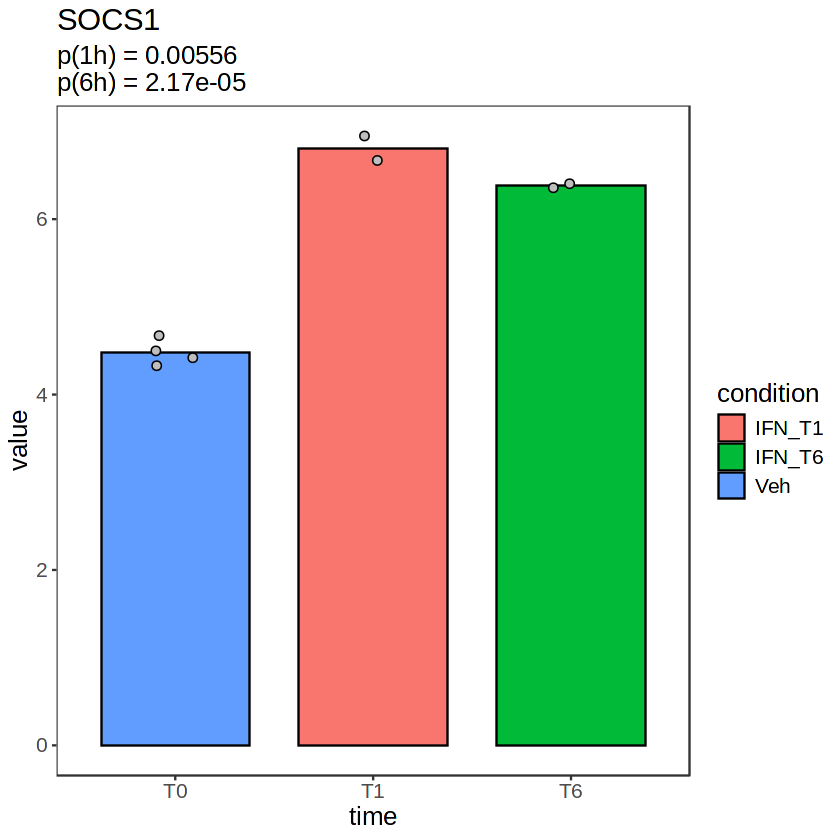

In [382]:
p4

In [370]:
t.test(p1[[1]][p1[[1]]$time=="T1",]$value, p1[[1]][p1[[1]]$time=="T0",]$value, alternative="greater")
t.test(p1[[1]][p1[[1]]$time=="T6",]$value, p1[[1]][p1[[1]]$time=="T0",]$value, alternative="greater")


	Welch Two Sample t-test

data:  p1[[1]][p1[[1]]$time == "T1", ]$value and p1[[1]][p1[[1]]$time == "T0", ]$value
t = 5.3707, df = 1.1361, p-value = 0.04797
alternative hypothesis: true difference in means is greater than 0
95 percent confidence interval:
 0.04616915        Inf
sample estimates:
mean of x mean of y 
 3.190157  1.932802 



	Welch Two Sample t-test

data:  p1[[1]][p1[[1]]$time == "T6", ]$value and p1[[1]][p1[[1]]$time == "T0", ]$value
t = 10.383, df = 1.0579, p-value = 0.02701
alternative hypothesis: true difference in means is greater than 0
95 percent confidence interval:
 1.621016      Inf
sample estimates:
mean of x mean of y 
 5.572952  1.932802 


In [369]:
t.test(alternativ

gene_name,name,value,condition,time,treatment
<chr>,<chr>,<dbl>,<chr>,<chr>,<chr>
GBP5,IFN_T1_r1,3.416840,IFN_T1,T1,IFN
GBP5,IFN_T1_r2,2.963474,IFN_T1,T1,IFN
GBP5,Veh_T1_r1,2.087463,Veh,T0,Veh
GBP5,Veh_T1_r2,1.863938,Veh,T0,Veh
GBP5,IFN_T6_r1,5.227279,IFN_T6,T6,IFN
GBP5,IFN_T6_r2,5.918625,IFN_T6,T6,IFN
GBP5,Veh_T6_r1,1.823749,Veh,T0,Veh
GBP5,Veh_T6_r2,1.956057,Veh,T0,Veh
